In [79]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import train_test_split
from statsmodels.tsa.deterministic import DeterministicProcess
import warnings
warnings.filterwarnings('ignore')

# ==============================================================================
# FASE 1: PERSIAPAN DATA & FEATURE ENGINEERING
# ==============================================================================
# 1. Load dataset & set index
df = pd.read_csv('DailyDelhiClimateTest.csv')
print(df)
df['date'] = pd.to_datetime(df['date']).dt.normalize()
df.set_index('date', inplace=True)
df.sort_index(inplace=True)
print(df)

           date   meantemp   humidity  wind_speed  meanpressure
0    2017-01-01  15.913043  85.869565    2.743478     59.000000
1    2017-01-02  18.500000  77.222222    2.894444   1018.277778
2    2017-01-03  17.111111  81.888889    4.016667   1018.333333
3    2017-01-04  18.700000  70.050000    4.545000   1015.700000
4    2017-01-05  18.388889  74.944444    3.300000   1014.333333
..          ...        ...        ...         ...           ...
109  2017-04-20  34.500000  27.500000    5.562500    998.625000
110  2017-04-21  34.250000  39.375000    6.962500    999.875000
111  2017-04-22  32.900000  40.900000    8.890000   1001.600000
112  2017-04-23  32.875000  27.500000    9.962500   1002.125000
113  2017-04-24  32.000000  27.142857   12.157143   1004.142857

[114 rows x 5 columns]
             meantemp   humidity  wind_speed  meanpressure
date                                                      
2017-01-01  15.913043  85.869565    2.743478     59.000000
2017-01-02  18.500000  77.22222

In [80]:
print(f"\nFrekuensi awal: {df.index.freq}") 

df = df.resample('D').ffill()
print("=== Data Info Awal ===")
print(f"Shape: {df.shape}")
print(df.head(3))


Frekuensi awal: None
=== Data Info Awal ===
Shape: (114, 4)
             meantemp   humidity  wind_speed  meanpressure
date                                                      
2017-01-01  15.913043  85.869565    2.743478     59.000000
2017-01-02  18.500000  77.222222    2.894444   1018.277778
2017-01-03  17.111111  81.888889    4.016667   1018.333333


In [81]:
# 2. Ekstraksi Fitur Dinamis (Lag)
df['Lag_1'] = df['meantemp'].shift(1)

# 3. Ekstraksi Fitur Kalender (One-Hot Encoding Hari)
df['Nama_Hari'] = df.index.day_name()
dummy_historis = pd.get_dummies(df['Nama_Hari'], prefix='Hari', drop_first=True, dtype=int)
kolom_dummy = list(dummy_historis.columns)

# 4. Ekstraksi Fitur Tren dengan statsmodels
dp = DeterministicProcess(index=df.index, constant=True, order=1, drop=True)
X_tren_historis = dp.in_sample()

# Gabungkan seluruh fitur
df_lengkap = pd.concat([df, X_tren_historis, dummy_historis], axis=1)

# Buang baris pertama yang kosong karena Lag_1
df_bersih = df_lengkap.dropna()

df_bersih

,meantemp,humidity,wind_speed,meanpressure,Lag_1,Nama_Hari,const,trend,Hari_Monday,Hari_Saturday,Hari_Sunday,Hari_Thursday,Hari_Tuesday,Hari_Wednesday
date,,,,,,,,,,,,,,
2017-01-02,18.500000,77.222222,2.894444,1018.277778,15.913043,Monday,1.0,2.0,1,0,0,0,0,0
2017-01-03,17.111111,81.888889,4.016667,1018.333333,18.500000,Tuesday,1.0,3.0,0,0,0,0,1,0
2017-01-04,18.700000,70.050000,4.545000,1015.700000,17.111111,Wednesday,1.0,4.0,0,0,0,0,0,1
2017-01-05,18.388889,74.944444,3.300000,1014.333333,18.700000,Thursday,1.0,5.0,0,0,0,1,0,0
2017-01-06,19.318182,79.318182,8.681818,1011.772727,18.388889,Friday,1.0,6.0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2017-04-20,34.500000,27.500000,5.562500,998.625000,33.500000,Thursday,1.0,110.0,0,0,0,1,0,0
2017-04-21,34.250000,39.375000,6.962500,999.875000,34.500000,Friday,1.0,111.0,0,0,0,0,0,0
2017-04-22,32.900000,40.900000,8.890000,1001.600000,34.250000,Saturday,1.0,112.0,0,1,0,0,0,0


In [82]:
# ==============================================================================
# FASE 2: DATA SPLITTING (TRAIN & TEST)
# ==============================================================================
# Susun urutan fitur (Pastikan sesuai)
fitur_kunci = ['const', 'trend', 'Lag_1'] + kolom_dummy

X = df_bersih[fitur_kunci]
y = df_bersih['meantemp']

# Split data: 80% Train, 20% Test (shuffle=False WAJIB untuk Time Series)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False)


Memulai Looping Prediksi pada Data Test...

=== Tabel Perbandingan Aktual vs Prediksi (10 Terakhir) ===
               Aktual  Prediksi  Error  Abs_Error
date                                             
2017-04-15  31.222222     29.98   1.24       1.24
2017-04-16  31.000000     30.84   0.16       0.16
2017-04-17  32.555556     30.81   1.75       1.75
2017-04-18  34.000000     30.72   3.28       3.28
2017-04-19  33.500000     31.27   2.23       2.23
2017-04-20  34.500000     31.45   3.05       3.05
2017-04-21  34.250000     31.26   2.99       2.99
2017-04-22  32.900000     31.01   1.89       1.89
2017-04-23  32.875000     31.92   0.95       0.95
2017-04-24  32.000000     31.92   0.08       0.08

Mean Absolute Error (MAE): 1.6494
Root Mean Squared Error (RMSE): 2.0015


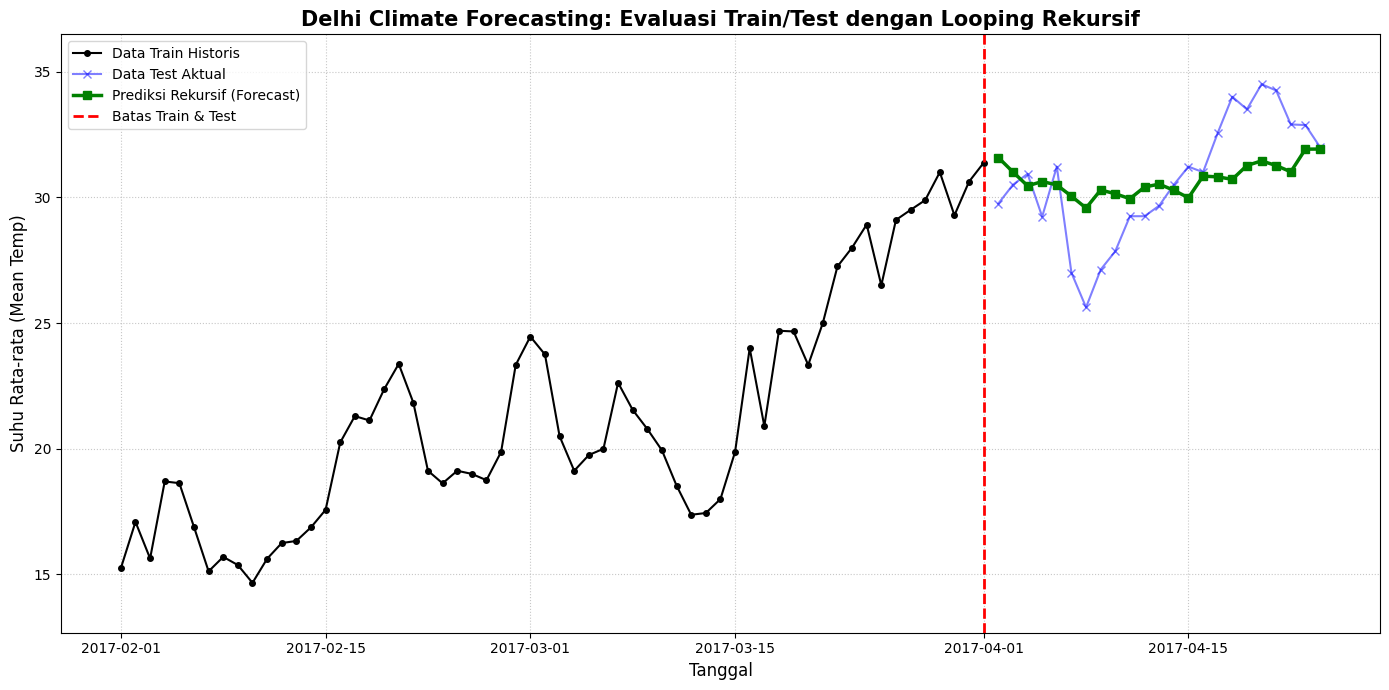

In [83]:
# ==============================================================================
# FASE 3: PELATIHAN MODEL (HANYA MENGGUNAKAN DATA TRAIN)
# ==============================================================================
# Matikan intercept karena 'const' sudah ada dari DeterministicProcess
model = LinearRegression(fit_intercept=False)
model.fit(X_train, y_train)

# ==============================================================================
# FASE 4: LOOPING REKURSIF PADA DATA TEST (TRUE FORECASTING)
# ==============================================================================
# Tangkap memori suhu hari TERAKHIR dari data TRAINING
nilai_lag_terakhir = y_train.iloc[-1]
prediksi_suhu = []

# Menggunakan X_test sebagai 'Blueprint' karena sudah berisi Tren dan Hari dummy
X_test_rekursif = X_test.copy()

print("\nMemulai Looping Prediksi pada Data Test...")
for i in range(len(X_test_rekursif)):
    # Ambil baris ke-i dari Data Test
    baris_hari_ini = X_test_rekursif.iloc[[i]].copy()
    
    # SUNTIKKAN Lag dinamis (Bukan dari data asli, tapi dari memori)
    baris_hari_ini['Lag_1'] = nilai_lag_terakhir
    
    # Eksekusi Prediksi
    X_prediksi = baris_hari_ini[fitur_kunci]
    prediksi_hari_ini = model.predict(X_prediksi)[0]
    prediksi_suhu.append(prediksi_hari_ini)
    
    # Update memori: Tebakan hari ini menjadi Lag_1 untuk putaran besok
    nilai_lag_terakhir = prediksi_hari_ini

# Simpan hasil rekursif
X_test_rekursif['Prediksi_meantemp'] = prediksi_suhu

# ==============================================================================
# FASE 5: EVALUASI & VISUALISASI
# ==============================================================================
y_pred = X_test_rekursif['Prediksi_meantemp']

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

# Membuat Tabel Perbandingan
hasil_df = pd.DataFrame({
    'Aktual': y_test.values,
    'Prediksi': np.round(y_pred.values, 2)
}, index=y_test.index)

hasil_df['Error'] = np.round(hasil_df['Aktual'] - hasil_df['Prediksi'], 2)
hasil_df['Abs_Error'] = np.round(np.abs(hasil_df['Error']), 2)

print("\n=== Tabel Perbandingan Aktual vs Prediksi (10 Terakhir) ===")
print(hasil_df.tail(10))
print("\n" + "="*50)
print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print("="*50)

# ----------------- VISUALISASI -----------------
plt.figure(figsize=(14, 7))

# Plot Data Train (Tampilkan 60 hari terakhir saja agar tidak terlalu rapat)
plt.plot(y_train.index[-60:], y_train.iloc[-60:], marker='o', color='black', markersize=4, label='Data Train Historis')

# Plot Data Test Aktual vs Prediksi
plt.plot(y_test.index, y_test, marker='x', color='blue', alpha=0.5, label='Data Test Aktual')
plt.plot(y_test.index, y_pred, marker='s', color='green', linewidth=2.5, label='Prediksi Rekursif (Forecast)')

plt.axvline(x=y_train.index[-1], color='red', linestyle='--', linewidth=2, label='Batas Train & Test')

plt.title('Delhi Climate Forecasting: Evaluasi Train/Test dengan Looping Rekursif', fontsize=15, fontweight='bold')
plt.xlabel('Tanggal', fontsize=12)
plt.ylabel('Suhu Rata-rata (Mean Temp)', fontsize=12)
plt.legend(loc='upper left')
plt.grid(True, linestyle=':', alpha=0.7)
plt.margins(y=0.1)
plt.tight_layout()

plt.show()

Musiman

In [84]:
import pandas as pd
from statsmodels.tsa.deterministic import DeterministicProcess

# Pembuatan rentang waktu 4 bulan
waktu_dummy = pd.date_range('2026-01-01', periods=4, freq='MS')
df_dummy = pd.DataFrame(index=waktu_dummy)

# Ekstraksi fitur dummy musiman (period=12 untuk data bulanan)
dp_dummy = DeterministicProcess(
    index=df_dummy.index,
    constant=False,
    seasonal=True,
    period=12,
    drop=True
)
X_musiman_dummy = dp_dummy.in_sample()

print("=== Matriks Variabel Dummy Musiman ===")
print(X_musiman_dummy.head(4))

=== Matriks Variabel Dummy Musiman ===
            s(1,12)  s(2,12)  s(3,12)  s(4,12)
2026-01-01      1.0      0.0      0.0      0.0
2026-02-01      0.0      1.0      0.0      0.0
2026-03-01      0.0      0.0      1.0      0.0
2026-04-01      0.0      0.0      0.0      1.0


In [85]:
import numpy as np
from statsmodels.tsa.deterministic import Fourier

# Menggunakan data harian selama 10 hari
waktu_fourier = pd.date_range('2026-01-01', periods=10, freq='D')
df_fourier = pd.DataFrame(index=waktu_fourier)

# Membuat komponen Fourier untuk siklus tahunan (period=365.25), menggunakan 1 orde (1 pasang Sin/Cos)
fourier_gen = Fourier(period=365.25, order=1)

dp_fourier = DeterministicProcess(
    index=df_fourier.index,
    constant=False,
    additional_terms=[fourier_gen],
    drop=True
)
X_musiman_fourier = dp_fourier.in_sample()

print("=== Matriks Deret Fourier (Orde 1) ===")
print(X_musiman_fourier.round(4).head())

=== Matriks Deret Fourier (Orde 1) ===
            sin(1,365.25)  cos(1,365.25)
2026-01-01         0.0000         1.0000
2026-01-02         0.0172         0.9999
2026-01-03         0.0344         0.9994
2026-01-04         0.0516         0.9987
2026-01-05         0.0688         0.9976


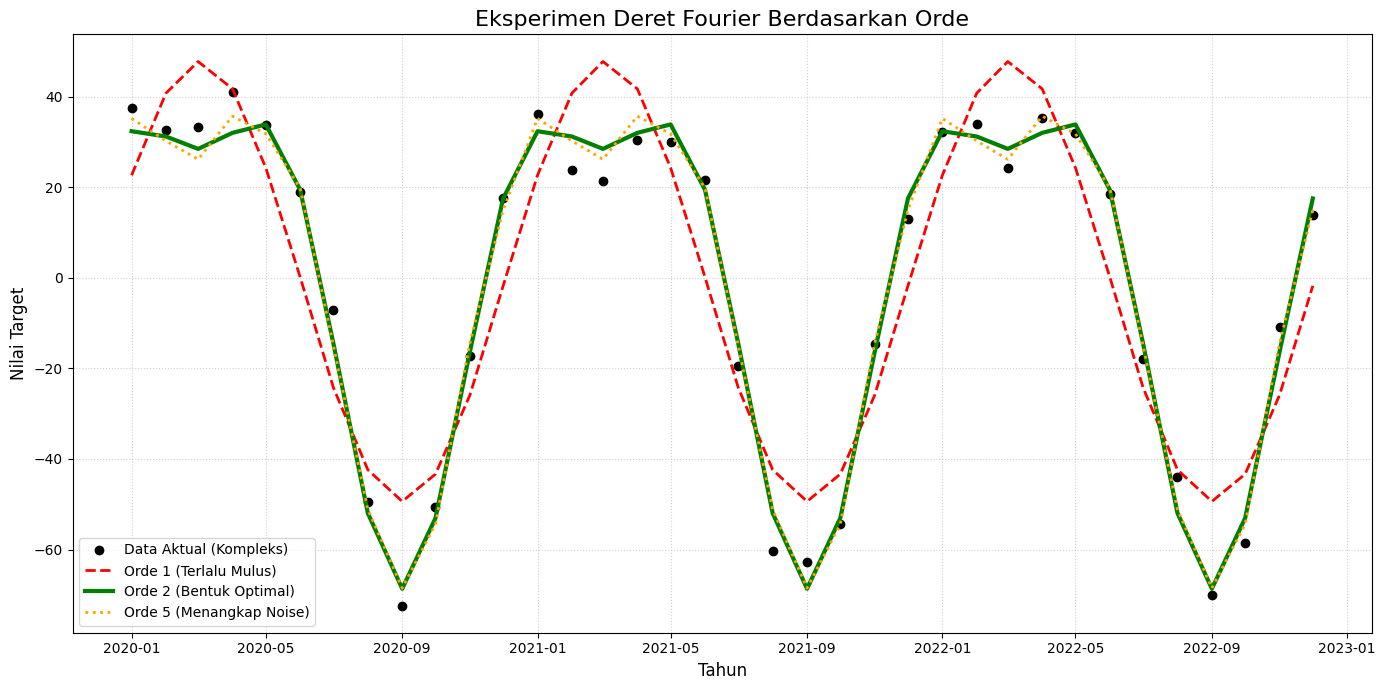

In [86]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.deterministic import DeterministicProcess, Fourier
from sklearn.linear_model import LinearRegression

np.random.seed(42)
waktu = pd.date_range('2020-01-01', periods=36, freq='MS') # 3 Tahun
t = np.arange(1, 37)

# Pola buatan: Puncak utama di pertengahan tahun, puncak kecil di akhir tahun
pola_kompleks = 50 * np.sin(2 * np.pi * t / 12) + 20 * np.cos(4 * np.pi * t / 12) + np.random.normal(0, 5, 36)
df = pd.DataFrame({'Target': pola_kompleks}, index=waktu)

def latih_fourier(orde, df_target):
    # Definisi Deret Fourier sesuai input orde
    fourier_gen = Fourier(period=12, order=orde)
    
    # Ekstraksi Matriks
    dp = DeterministicProcess(index=df_target.index, constant=True, additional_terms=[fourier_gen], drop=True)
    X_matriks = dp.in_sample()
    
    # Pelatihan Regresi
    model = LinearRegression(fit_intercept=False)
    model.fit(X_matriks, df_target['Target'])
    
    # Kembalikan hasil prediksi untuk di-plot
    return model.predict(X_matriks)

# MENGHITUNG PREDIKSI UNTUK ORDE 1, 2, DAN 5
prediksi_orde_1 = latih_fourier(orde=1, df_target=df)
prediksi_orde_2 = latih_fourier(orde=2, df_target=df)
prediksi_orde_5 = latih_fourier(orde=5, df_target=df)

# VISUALISASI KOMPARATIF
plt.figure(figsize=(14, 7))

# Plot Titik Data Aktual
plt.plot(df.index, df['Target'], color='black', marker='o', linestyle='', label='Data Aktual (Kompleks)')

# Plot Hasil Orde 1 (Terlalu Kaku / Underfitting)
plt.plot(df.index, prediksi_orde_1, color='red', linestyle='--', linewidth=2, label='Orde 1 (Terlalu Mulus)')

# Plot Hasil Orde 2 (Ideal)
plt.plot(df.index, prediksi_orde_2, color='green', linewidth=3, label='Orde 2 (Bentuk Optimal)')

# Plot Hasil Orde 5 (Terlalu Keriting / Overfitting)
plt.plot(df.index, prediksi_orde_5, color='orange', linestyle=':', linewidth=2, label='Orde 5 (Menangkap Noise)')

plt.title('Eksperimen Deret Fourier Berdasarkan Orde', fontsize=16)
plt.xlabel('Tahun', fontsize=12)
plt.ylabel('Nilai Target', fontsize=12)
plt.legend(loc='lower left')
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()

plt.show()

In [87]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.deterministic import DeterministicProcess, Fourier
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

np.random.seed(42)
total_bulan = 60 # 5 Tahun Data Historis
indeks_waktu = pd.date_range('2020-01-01', periods=total_bulan, freq='MS')

# Pembuatan rumus: Tren linier + Gelombang Sinus/Cosinus musiman + Noise
t = np.arange(1, total_bulan + 1)
tren_dasar = 100 + (1.5 * t)
gelombang_musiman = 30 * np.sin(2 * np.pi * t / 12) + 15 * np.cos(2 * np.pi * t / 12)
penumpang_aktual = tren_dasar + gelombang_musiman + np.random.normal(0, 5, total_bulan)

df_maskapai = pd.DataFrame({'Penumpang': penumpang_aktual}, index=indeks_waktu)
df_maskapai = df_maskapai.asfreq('MS')

print("=== Data Mentah Maskapai ===")
print(df_maskapai.head())

=== Data Mentah Maskapai ===
             Penumpang
2020-01-01  131.973952
2020-02-01  135.789441
2020-03-01  137.738443
2020-04-01  132.095911
2020-05-01  108.338852


In [88]:
# Definisi Fourier untuk data bulanan (1 siklus = 12 bulan), kompleksitas 2 orde (4 kolom)
fourier_terms = Fourier(period=12, order=2)

# Menggabungkan Tren Linier, Tren Kuadratik, dan Fourier dalam satu proses
dp_terpadu = DeterministicProcess(
    index=df_maskapai.index,
    constant=True,
    order=2, # Tren kuadratik (trend, trend_squared)
    additional_terms=[fourier_terms],
    drop=True
)

X_fitur = dp_terpadu.in_sample()
y_target = df_maskapai['Penumpang']

print("\n=== Matriks (Tren + Fourier) ===")
print(X_fitur.head())


=== Matriks (Tren + Fourier) ===
            const  trend  trend_squared  sin(1,12)     cos(1,12)  \
2020-01-01    1.0    1.0            1.0   0.000000  1.000000e+00   
2020-02-01    1.0    2.0            4.0   0.500000  8.660254e-01   
2020-03-01    1.0    3.0            9.0   0.866025  5.000000e-01   
2020-04-01    1.0    4.0           16.0   1.000000  6.123234e-17   
2020-05-01    1.0    5.0           25.0   0.866025 -5.000000e-01   

               sin(2,12)  cos(2,12)  
2020-01-01  0.000000e+00        1.0  
2020-02-01  8.660254e-01        0.5  
2020-03-01  8.660254e-01       -0.5  
2020-04-01  1.224647e-16       -1.0  
2020-05-01 -8.660254e-01       -0.5  


In [89]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X_fitur, y_target, test_size=0.2, 
                                                    shuffle=False, random_state=42)

# PELATIHAN MODEL REGRESI
model_musiman = LinearRegression(fit_intercept=False)
model_musiman.fit(X_train, y_train)

# Evaluasi Data Ujian
prediksi_uji = model_musiman.predict(X_test)
error_mae = mean_absolute_error(y_test, prediksi_uji)

print(f"\n=== Hasil Validasi Model ===")
print(f"Rata-rata Kesalahan (MAE): {error_mae:.2f} Penumpang")


=== Hasil Validasi Model ===
Rata-rata Kesalahan (MAE): 3.34 Penumpang


In [90]:
model_musiman = LinearRegression(fit_intercept=False)
model_musiman.fit(X_fitur, y_target)

horizon_masa_depan = 24

X_masa_depan = dp_terpadu.out_of_sample(steps=horizon_masa_depan)

prediksi_masa_depan = model_musiman.predict(X_masa_depan)

df_hasil_forecast = pd.DataFrame({
    'Prediksi_Penumpang': np.round(prediksi_masa_depan, 0)
}, index=X_masa_depan.index)

print(df_hasil_forecast.head())

            Prediksi_Penumpang
2025-01-01               221.0
2025-02-01               227.0
2025-03-01               225.0
2025-04-01               216.0
2025-05-01               204.0


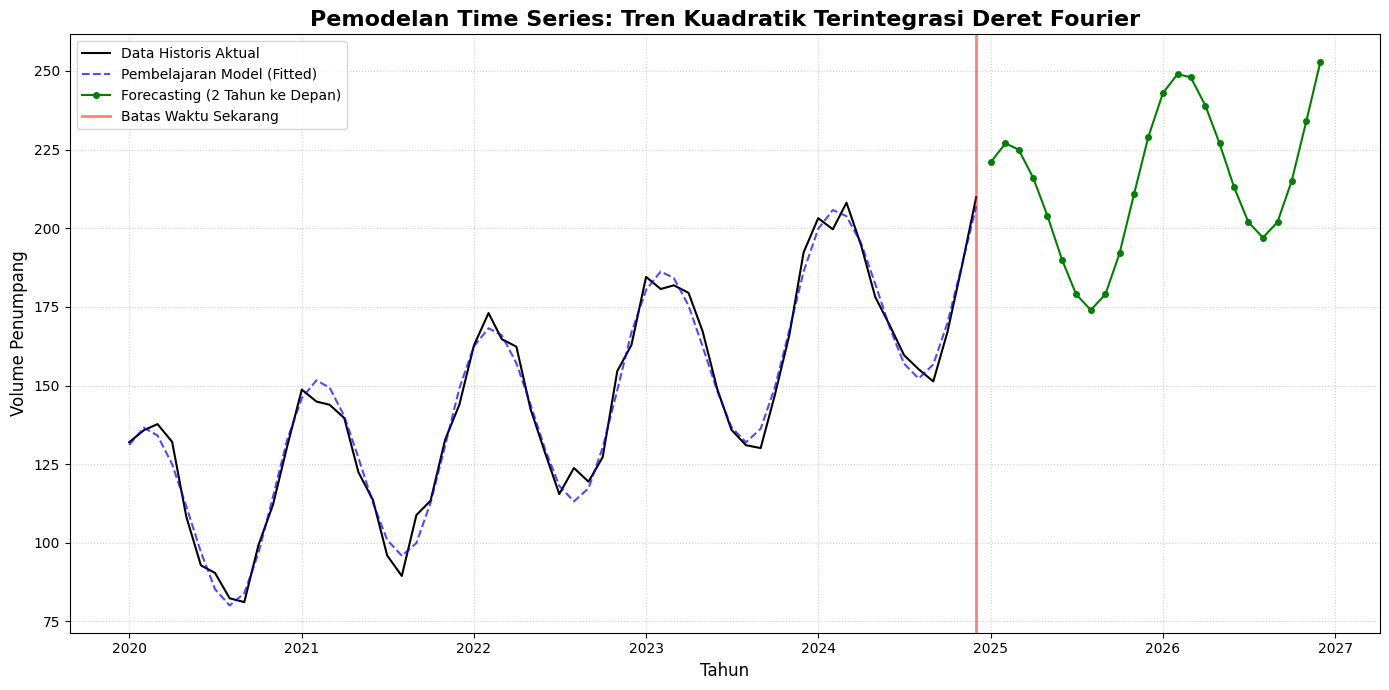

In [91]:
# VISUALISASI KESELURUHAN
plt.figure(figsize=(14, 7))

# Plot Data Historis
plt.plot(df_maskapai.index, 
         df_maskapai['Penumpang'], 
         color='black', label='Data Historis Aktual')

# Plot Garis Fit Model (Pembelajaran Masa Lalu)
plt.plot(X_fitur.index, model_musiman.predict(X_fitur), 
         color='blue', linestyle='--', alpha=0.7, label='Pembelajaran Model (Fitted)')

# Plot True Forecasting Masa Depan
plt.plot(df_hasil_forecast.index, df_hasil_forecast['Prediksi_Penumpang'], 
         color='green', marker='o', markersize=4, label='Forecasting (2 Tahun ke Depan)')

# Estetika Grafik
plt.axvline(x=df_maskapai.index[-1], color='red', 
            linestyle='-', linewidth=2, alpha=0.5, label='Batas Waktu Sekarang')
plt.title('Pemodelan Time Series: Tren Kuadratik Terintegrasi Deret Fourier', fontsize=16, fontweight='bold')
plt.xlabel('Tahun', fontsize=12)
plt.ylabel('Volume Penumpang', fontsize=12)
plt.legend(loc='upper left')
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()

plt.show()